## Лабораторная работа 03 — Классическое выравнивание и N-граммные языковые модели

**Цель:** Дополнить недостающие вычисления в имеющихся модулях Python. Изучить имеющиеся скрипты и реализовать основные вычисления для алгоритма Витерби, биграммной языковой модели и комбинирования оценок гипотез.

**Выполнила:** Иванова М.К.  
**Проверил:** Романенко А.Н.

In [ ]:
from pathlib import Path
import sys, json, csv, math

LAB_ROOT = Path.cwd()

from scripts.viterbi_alignment import viterbi_align
from scripts.bigram_lm import BigramLM, tokenize
from scripts.combine_candidate_scores import rank_candidates
from scripts.run_lab_03 import run_lab
from IPython.display import SVG, display


DATA = LAB_ROOT / "data"
REF  = LAB_ROOT / "outputs_reference"
OUT  = LAB_ROOT / "outputs"

In [7]:
summary = run_lab(DATA, OUT)
summary

{'alignment_path': [0, 1, 1, 2, 3, 4],
 'alignment_total_cost': 3.0,
 'alternative_path_cost': 3.7,
 'candidate_rankings': {'0.0': ['acoustic_favorite', 'language_favorite'],
  '0.5': ['language_favorite', 'acoustic_favorite'],
  '1.0': ['language_favorite', 'acoustic_favorite']},
 'note': 'Стоимость и акустические баллы синтетические: это учебный пример, а не вывод модели.'}

### Часть A — Выравнивание по алгоритму Витерби

In [8]:
alignment = json.loads((DATA / "toy_alignment_costs.json").read_text(encoding="utf-8"))
print("frames:", alignment["frame_labels"])
print("states:", alignment["state_labels"])
print("costs (T×S):")
for f, row in zip(alignment["frame_labels"], alignment["costs"]):
    print(f"{f:>6}", [f"{v:6.2f}" for v in row])
print("known_alternative:", alignment["known_alternative"])

frames: ['f1', 'f2', 'f3', 'f4', 'f5', 'f6']
states: ['sil_start', '/y/', '/e/', '/s/', 'sil_end']
costs (T×S):
    f1 ['  0.40', '  9.00', '  9.00', '  9.00', '  9.00']
    f2 ['  9.00', '  0.70', '  9.00', '  9.00', '  9.00']
    f3 ['  9.00', '  0.50', '  1.20', '  9.00', '  9.00']
    f4 ['  9.00', '  9.00', '  0.60', '  9.00', '  9.00']
    f5 ['  9.00', '  9.00', '  9.00', '  0.50', '  9.00']
    f6 ['  9.00', '  9.00', '  9.00', '  9.00', '  0.30']
known_alternative: {'path': [0, 1, 2, 2, 3, 4], 'total_cost': 3.7}


In [9]:
path, total_cost = viterbi_align(
    alignment["costs"], start_state=0,
    final_state=len(alignment["state_labels"]) - 1,
)
print("path indices:", path)
print("path labels :", [alignment["state_labels"][s] for s in path])
print(f"total_cost  : {total_cost:.3f}")

cum = 0.0
rows = []
for t, s in enumerate(path):
    e = float(alignment["costs"][t][s]); cum += e
    rows.append((alignment["frame_labels"][t], s, alignment["state_labels"][s], e, cum))
rows

path indices: [0, 1, 1, 2, 3, 4]
path labels : ['sil_start', '/y/', '/y/', '/e/', '/s/', 'sil_end']
total_cost  : 3.000


[('f1', 0, 'sil_start', 0.4, 0.4),
 ('f2', 1, '/y/', 0.7, 1.1),
 ('f3', 1, '/y/', 0.5, 1.6),
 ('f4', 2, '/e/', 0.6, 2.2),
 ('f5', 3, '/s/', 0.5, 2.7),
 ('f6', 4, 'sil_end', 0.3, 3.0)]

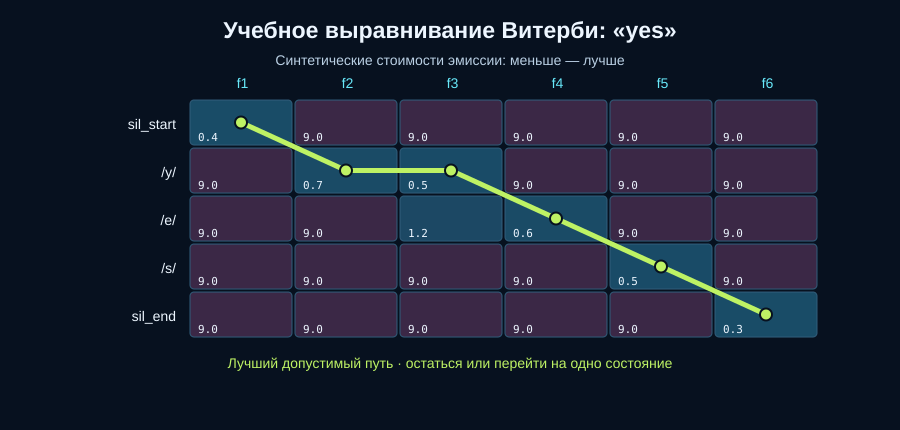

In [ ]:
display(SVG(filename=str(OUT / "viterbi_trellis.svg")))

In [11]:
alt_cost = alignment["known_alternative"]["total_cost"]
print(f"best = {total_cost:.3f}")
print(f"alternative = {alt_cost:.3f}")
print(f"diff = {alt_cost - total_cost:.3f}")

best = 3.000
alternative = 3.700
diff = 0.700


**Лучший путь.** Путь: `<sil_start, /y/, /y/, /e/, /s/, sil_end>`, общая стоимость **3.000**.
Накопленные стоимости по кадрам: `f1=0.4`, `f2=1.1`, `f3=1.6`, `f4=2.2`, `f5=2.7`, `f6=3.0` (см. таблицу выше).

**Где остаёмся, где переходим.**
- **Остаёмся:** кадр `f2` → `f3`, состояние `/y/` (индекс 1 → 1) — звук «тянется» на два кадра.
- **Переходим:** кадр `f3` → `f4`, переход `/y/ → /e/` (индекс 1 → 2); либо `f5` → `f6`, переход `/s/ → sil_end` (3 → 4).

Лучший путь со стоимостью `3.0`, альтернативный `3.7`. Альтернативный путь `<sil_start, /y/, /e/, /e/, /s/, sil_end>` дороже на 0.7.

**Тепловая карта.** Кодирует стоимости эмиссии `costs[frame][state]`: тёмно-синий/зелёный = низкая стоимость (лучше), фиолетовый (9.0) = самая высокая стоимость (хуже). Зелёная ломаная - найденный лучший путь.
- **Две ячейки с низкой стоимостью:** `f3, /y/` (0.5) и `f5, /s/` (0.5).
- **Одна ячейка с высокой стоимостью:** любая из ячеек со значением `9.0` (например, `f1, /e/`), так как эти состояния акустически не подходят кадру.

### Часть B — Биграммная языковая модель слов

In [12]:
corpus = (DATA / "toy_lm_corpus.txt").read_text(encoding="utf-8").splitlines()
lm = BigramLM.train(corpus, k=0.5)

print("sentences:", len(corpus))
print("|V| (predictable):", len(lm.vocabulary), "->", sorted(lm.vocabulary))
print("C(<s>) =", lm.context_counts["<s>"], "(= число предложений)")
print("top contexts:", lm.context_counts.most_common(5))
print("top bigrams :", lm.bigram_counts.most_common(5))

h, w = "<s>", "yes"
C_hw = lm.bigram_counts[(h, w)]
C_h  = lm.context_counts[h]
k    = lm.k
num  = C_hw + k
den  = C_h + k * len(lm.vocabulary)
print(f"P({w}|{h}) = ({C_hw}+{k}) / ({C_h}+{k}*{len(lm.vocabulary)}) = {num/den:.6f}")
print("через метод:", lm.bigram_probability(h, w))

sentences: 7
|V| (predictable): 10 -> ['</s>', '<unk>', 'coffee', 'drink', 'green', 'like', 'strong', 'tea', 'they', 'we']
C(<s>) = 7 (= число предложений)
top contexts: [('<s>', 7), ('green', 5), ('tea', 5), ('we', 4), ('drink', 4)]
top bigrams : [(('green', 'tea'), 5), (('tea', '</s>'), 5), (('<s>', 'we'), 4), (('drink', 'green'), 3), (('<s>', 'they'), 3)]
P(yes|<s>) = (0+0.5) / (7+0.5*10) = 0.041667
через метод: 0.041666666666666664


In [13]:
candidates = json.loads((DATA / "toy_candidate_scores.json").read_text(encoding="utf-8"))
for c in candidates:
    c["lm_log_score"] = lm.sentence_logprob(c["transcript"])
    print(f"{c['candidate_id']:>3} {c['transcript']!r:>12}  lm={c['lm_log_score']:.6f}")

acoustic_favorite 'we drink strong coffee'  lm=-2.654739
language_favorite 'we drink green tea'  lm=-1.911720


**Размер словаря.** `|V| = 10` (8 слов корпуса + `<unk>` + `</s>`).  
Слова: `['</s>', '<unk>', 'coffee', 'drink', 'green', 'like', 'strong', 'tea', 'they', 'we']`.

**Пример контекста.** Для `h = <s>`: `C(<s>) = 7` (по числу предложений), `C(<s>, yes) = 0` (такой биграммы нет). 
`P(yes|<s>) = (0 + 0.5) / (7 + 0.5·10) = 0.5 / 12 ≈ 0.041667` - совпадает с `lm.bigram_probability` (вывод выше).

**`</s>` учитывается** в `sentence_logprob`; незнакомое слово `<unk>` (проверено на примере с "yes", которого нет в словаре).

**LM-оценки кандидатов.** 
- `acoustic_favorite` ("we drink strong coffee"): `-2.654739`
- `language_favorite` ("we drink green tea"): `-1.911720`

### Часть C — Акустические оценки и оценки языковой модели

In [ ]:
for lam in (0.0, 0.5, 1.0):
    ranked = rank_candidates(candidates, weight=lam)
    print(f"\nλ = {lam}")
    print(f"{'rank':>4} {'id':>4} {'transcript':>14} {'acoustic':>10} {'lm':>10} {'combined':>10}")
    for r, row in enumerate(ranked, 1):
        print(f"{r:>4} {row['candidate_id']:>4} {row['transcript']:>14} "
              f"{row['acoustic_log_score']:>10.6f} {row['lm_log_score']:>10.6f} "
              f"{row['combined_log_score']:>10.6f}")


λ = 0.0
rank   id     transcript   acoustic         lm   combined
   1 acoustic_favorite we drink strong coffee  -1.000000  -2.654739  -1.000000
   2 language_favorite we drink green tea  -1.200000  -1.911720  -1.200000

λ = 0.5
rank   id     transcript   acoustic         lm   combined
   1 language_favorite we drink green tea  -1.200000  -1.911720  -2.155860
   2 acoustic_favorite we drink strong coffee  -1.000000  -2.654739  -2.327369

λ = 1.0
rank   id     transcript   acoustic         lm   combined
   1 language_favorite we drink green tea  -1.200000  -1.911720  -3.111720
   2 acoustic_favorite we drink strong coffee  -1.000000  -2.654739  -3.654739


In [15]:
print((OUT / "candidate_scores.csv").read_text(encoding="utf-8")
      if (OUT / "candidate_scores.csv").exists()
      else (REF / "candidate_scores.csv").read_text(encoding="utf-8"))

lm_weight,rank,candidate_id,transcript,acoustic_log_score,lm_log_score,combined_log_score
0.00,1,acoustic_favorite,we drink strong coffee,-1.000000,-2.654739,-1.000000
0.00,2,language_favorite,we drink green tea,-1.200000,-1.911720,-1.200000
0.50,1,language_favorite,we drink green tea,-1.200000,-1.911720,-2.155860
0.50,2,acoustic_favorite,we drink strong coffee,-1.000000,-2.654739,-2.327369
1.00,1,language_favorite,we drink green tea,-1.200000,-1.911720,-3.111720
1.00,2,acoustic_favorite,we drink strong coffee,-1.000000,-2.654739,-3.654739



**λ = 0:** на первом месте `acoustic_favorite` ("we drink strong coffee"), acoustic = `-1.000000`, lm = `-2.654739`, combined = `-1.000000`.

**λ = 0.5:** на первом месте `language_favorite` ("we drink green tea"), acoustic = `-1.200000`, lm = `-1.911720`, combined = `-2.155860`.

При λ=0 LM не влияет, побеждает лучшая акустика: разрыв в пользу `acoustic_favorite` составляет **0.2** (от -1.0 до -1.2). 
Однако разрыв в оценках LM составляет **0.74** (от -1.91 у "green tea" до -2.65 у "strong coffee"). 
При λ=0.5 вклад LM перевешивает акустический разрыв: `0.5 * 0.74 = 0.37 > 0.2`. Поэтому `language_favorite` выходит на первое место. При λ=1.0 его преимущество только растёт.

## Выводы

- Оптимальная стоимость `3.0`.
- Оценки незнакомых слов (`<unk>`) не обнуляют вероятность.
- Ранжирование гипотез зависит от веса λ: при малом λ побеждает акустика, при росте λ — языковая модель.